In [1]:
import pandas as pd
import matplotlib.pyplot as plot
import matplotlib.dates as mdates
import seaborn as sns
from plotly.offline import plot as plt
import plotly.graph_objs as go
import time
from datetime import datetime, timedelta, date
import teradata
import  businessdays as bzd


start = time.time() 
system = "TERADBAWS.sicredi.net"
user = "P_USR_DL_GESTAO_RECURSOS"
passw = "JAW0b71329aadade35365afc6X"
udaExec = teradata.UdaExec (appName="TESTE", version="1.0", logConsole=False)
session = udaExec.connect(method="odbc", system=system,
        username=user, password=passw, Authentication="TDNEGO");


select_feriados = "Select DT from dl_Gestao_recursos.bas_cad_fer where tipo in ('3','2')"
feriados = pd.read_sql(select_feriados, session)
cal = bzd.Calendar(holidays=feriados.DT,weekdays=['Sunday','Saturday'])

data_inicial = cal.offset(datetime.now(),-180  )###DATA PADRÃO D-180
data_inicial = data_inicial.strftime('%Y-%m-%d') ###DATA PADRÃO D-180

data_final = cal.offset(datetime.now(),-1  )###DATA PADRÃO D-1
data_final = data_final.strftime('%Y-%m-%d') ###DATA PADRÃO D-1

#data_inicial='2023-01-01'
#data_final='2023-07-25'


lista = ['F26F28F30','F25N25F26','F25F27F29','F27F29F31','F28F31F33','F28F30F32','F24F25F27', 'F25F27F28','F25F26F27','F28F29F30']


lista_string = "','".join(map(str,lista))


Select = f"""
          SELECT DT
        , FLY
        , TX_FLY_PONTOS
        , AVG(TX_FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) AS MEDIA_6M
        , AVG(TX_FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) + 2*(STDDEV_SAMP(TX_FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_SUP_6M
        , AVG(TX_FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW) - 2*(STDDEV_SAMP(TX_FLY_PONTOS) OVER (PARTITION BY FLY ORDER BY DT ROWS BETWEEN 125 PRECEDING AND CURRENT ROW)) as LIM_INF_6M
        , CDI
        FROM(
        SELECT DI_B.DT
        , OREPLACE(DI_A.CONTRATO ||  DI_B.CONTRATO ||  DI_C.CONTRATO, 'DI1', '') AS FLY
        , DI_A.CONTRATO AS CONTRATO_A, DI_B.CONTRATO AS CONTRATO_B
        , DI_A.TAXA AS TAXA_A, DI_B.TAXA AS TAXA_B
        
        ,  (DI_c.TAXA - DI_b.TAXA) - (DI_B.TAXA - DI_A.TAXA) as TX_FLY_PONTOS
        , ((IDX.VALOR/3000+1)**252.000000-1)*100 AS CDI
        
        FROM DL_GESTAO_RECURSOS.VW_DI DI_B
        LEFT JOIN DL_GESTAO_RECURSOS.VW_DI DI_A ON DI_A.DT = DI_B.DT AND DI_A.DU < DI_B.DU
        LEFT JOIN DL_GESTAO_RECURSOS.VW_DI DI_C ON DI_C.DT = DI_B.DT AND DI_C.DU > DI_B.DU
        LEFT JOIN DL_GESTAO_RECURSOS.DU ON DU.DT = DI_B.DT
        LEFT JOIN DL_GESTAO_RECURSOS.IDX_INDEX IDX ON IDX.DATA = DI_B.DT AND IDX.CODINDEX = 'CDI'
        
        WHERE DI_A.CONTRATO IS NOT NULL) VW
        WHERE VW.DT between '{data_inicial}' and '{data_final}'
        AND FLY IN ('{lista_string}')
"""



fly = pd.read_sql(Select, session) 
fly.DT = pd.to_datetime(fly.DT, format='%Y-%m-%d')

   
pd.set_option('mode.chained_assignment', None)

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_35740\3800814382.py:23: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_35740\3800814382.py:72: UserWarning:

pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.



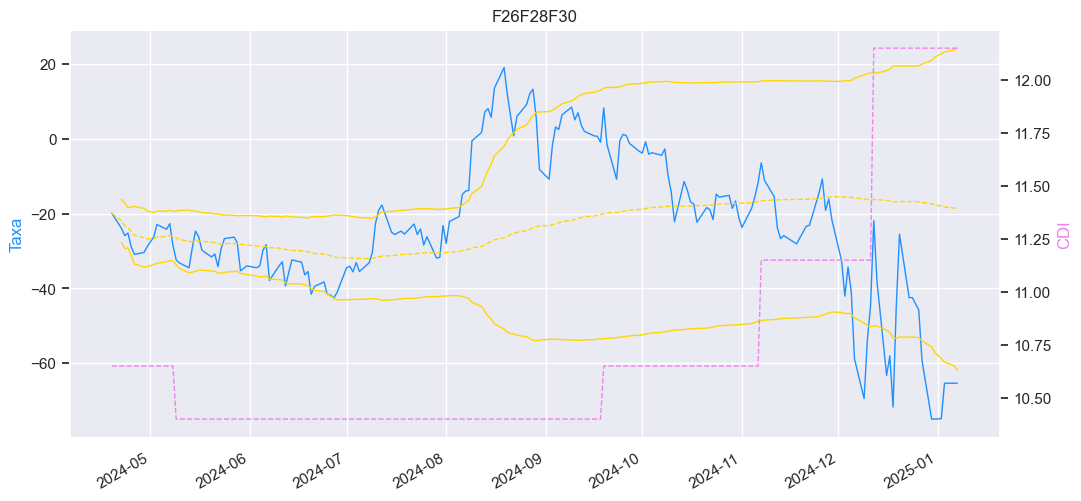

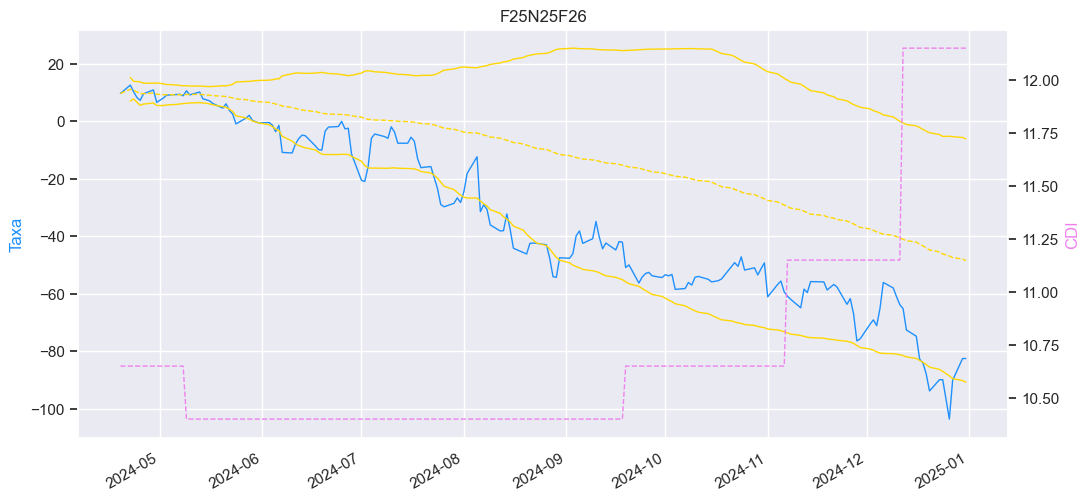

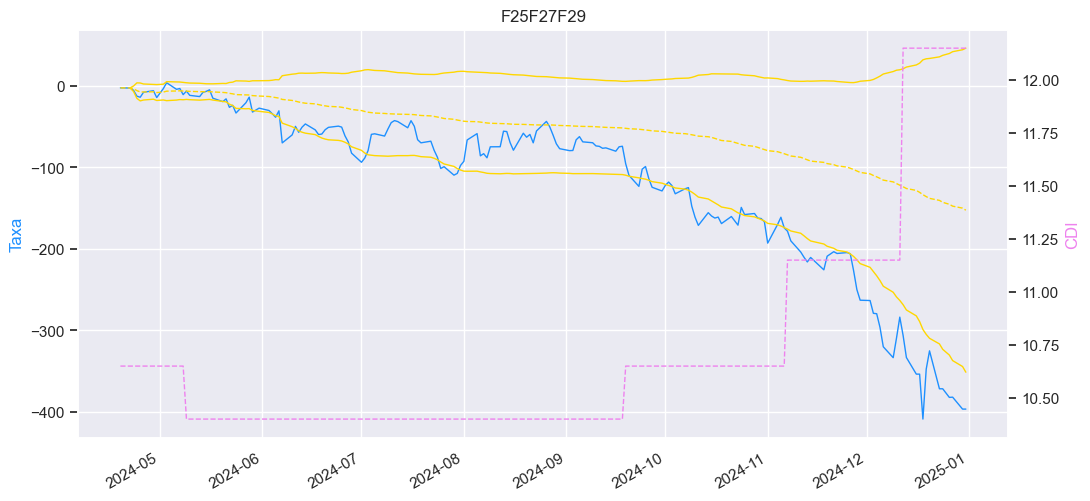

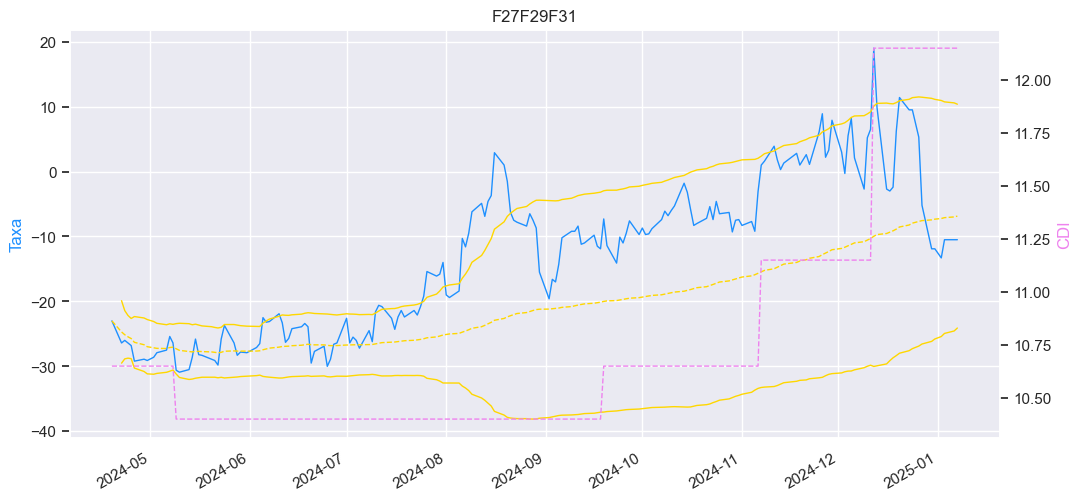

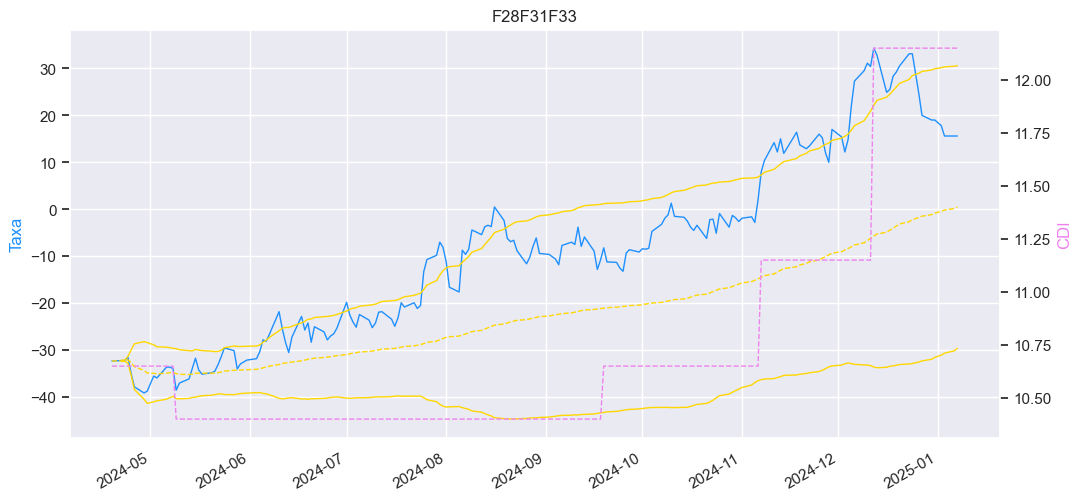

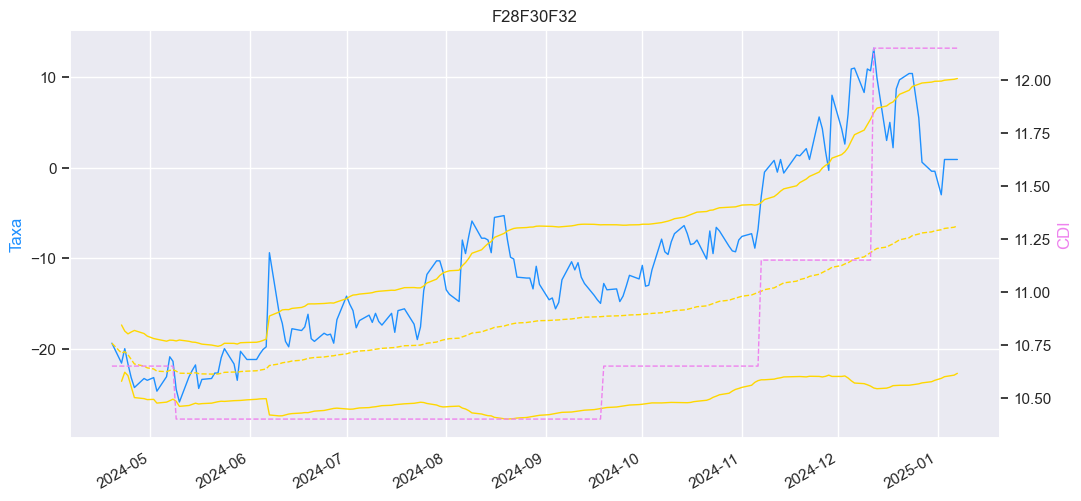

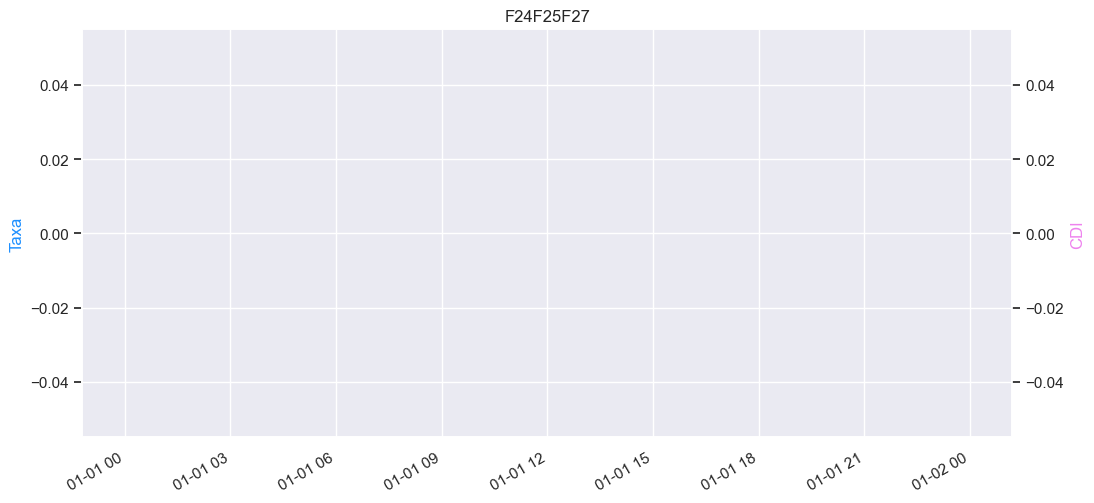

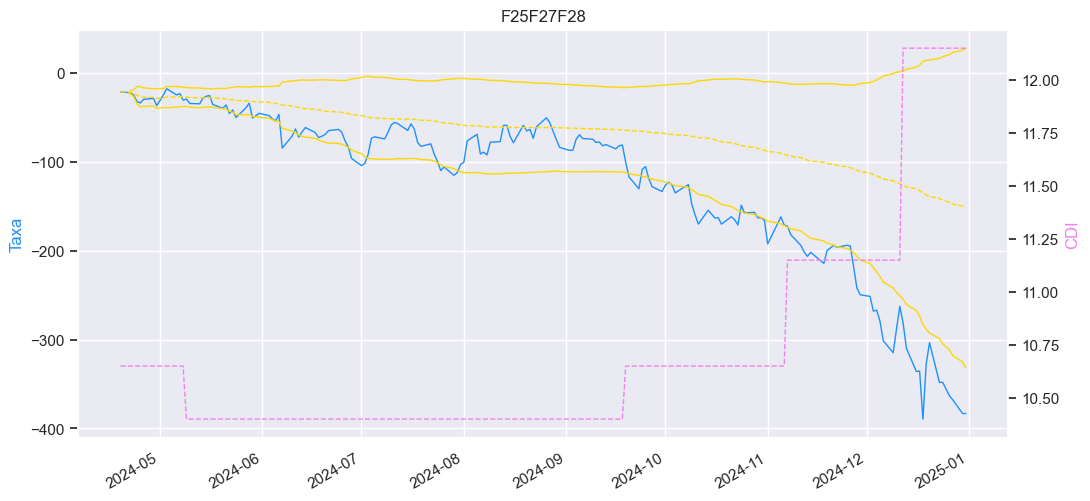

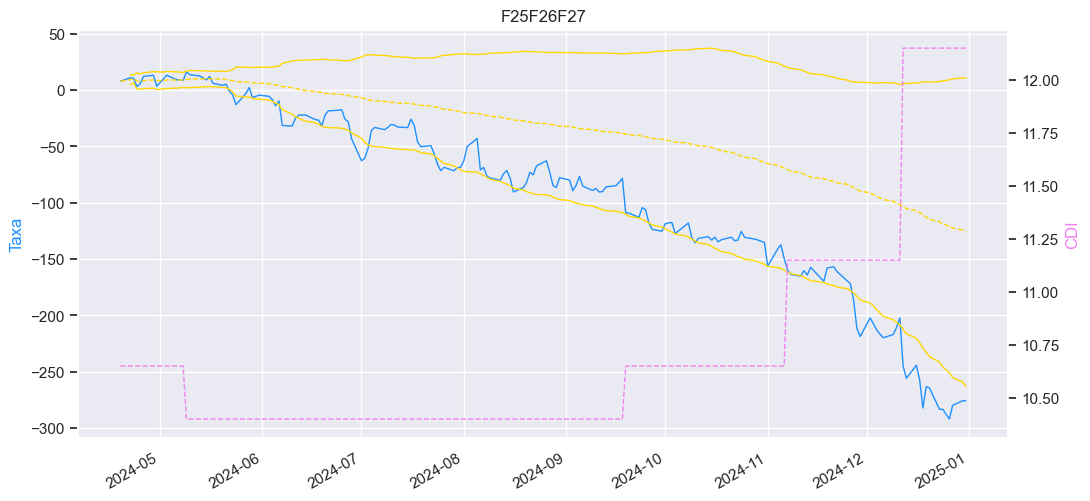

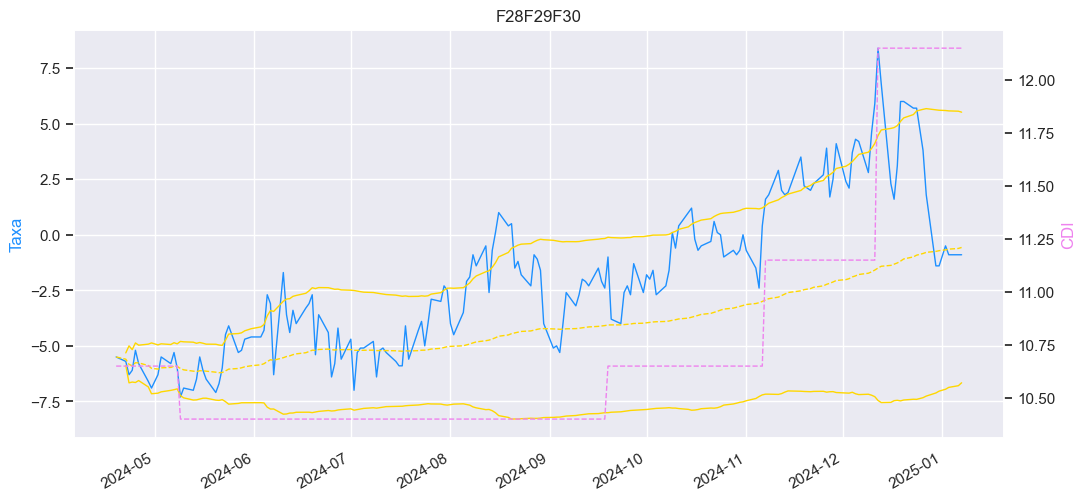

In [2]:
for x in lista: 
    fly_grafico = fly[fly.FLY == x]
    fly_grafico = fly_grafico.sort_values(by=['DT'])
    fly_nome = x


    sns.set(style="darkgrid", palette="Set2")
    plot.rcParams['figure.figsize'] = (12,6)

    fig, ax = plot.subplots()
    ax2 = ax.twinx()
    ax.plot(fly_grafico.DT,fly_grafico['TX_FLY_PONTOS']*10000, marker = '', color='dodgerblue',linestyle='-',linewidth=1,)
    ax.plot(fly_grafico.DT,fly_grafico['MEDIA_6M']*10000, marker='', color='gold',linestyle='--',linewidth=1)
    ax.plot(fly_grafico.DT,fly_grafico['LIM_INF_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax.plot(fly_grafico.DT,fly_grafico['LIM_SUP_6M']*10000, marker='', color='gold',linestyle='-',linewidth=1)
    ax2.plot(fly_grafico.DT,fly_grafico['CDI'], marker='', color='violet',linestyle='--',linewidth=1)
    ax.set_ylabel('Taxa', color='dodgerblue')
    ax2.set_ylabel('CDI', color='violet',labelpad=None)
    ax2.grid(visible=False)

    plot.title(fly_nome)
    #plot.ylabel('Taxa')
    plot.xlabel('Data')
    fig.autofmt_xdate()
    ax.fmt_xdata = mdates.DateFormatter('%Y-%m')
    plot.show()
    #plt.savefig('FLY.png', transparent = True)
    #fly_grafico.set_index('DT',inplace=True)

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning:

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.



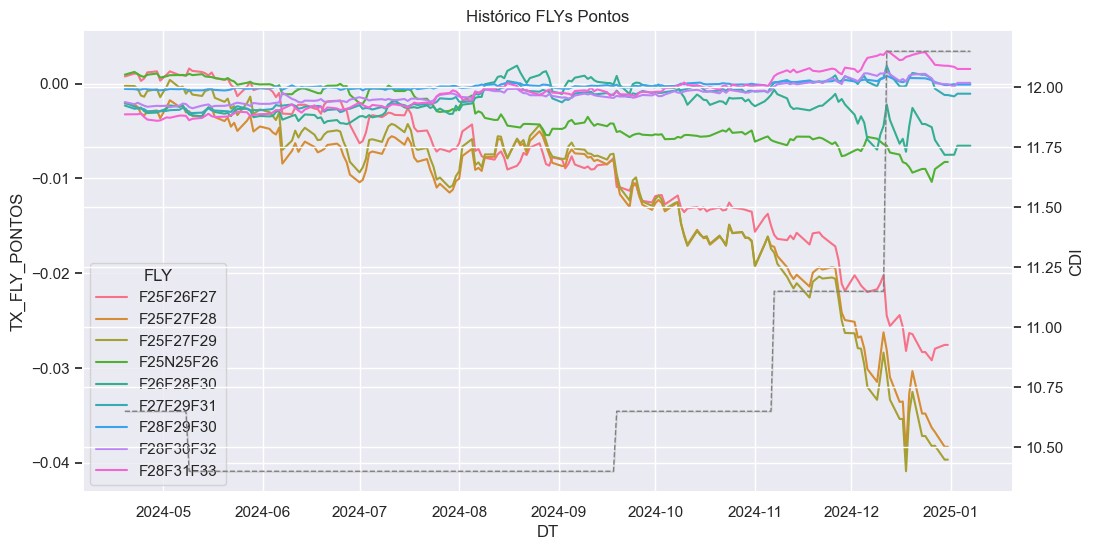

In [3]:
import matplotlib.pyplot as plot
df = fly.sort_values(by=['DT','FLY'])
df_grafico  = df[df['FLY'].isin(lista)]


sns.set(style="darkgrid", palette="Set2")
ax1 = sns.lineplot(x='DT', y='TX_FLY_PONTOS', data=df_grafico, hue='FLY')
ax2 = ax1.twinx()
ax2 = sns.lineplot(x='DT', y='CDI', data=df_grafico, marker='', color='gray',linestyle='--',linewidth=1)
ax1.set(title='Histórico FLYs Pontos')
plot.show()    